In [1]:
# EKG (WFDB) dosyalarını okumak için gerekli kütüphaneyi kuruyoruz
!pip install -q wfdb

!pip install neurokit2

In [2]:
# --- 1. Kütüphanelerin İçe Aktarılması ---
import neurokit2 as nk
import pandas as pd
import numpy as np
import wfdb
import matplotlib.pyplot as plt
import os
import random
import seaborn as sns

print("✓ Temel kütüphaneler yüklendi.")

✓ Temel kütüphaneler yüklendi.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# --- 2. Veri Yolu Yapılandırması ---
# Proje mimarinize göre Drive üzerindeki yollar
drive_base_path = '/content/drive/MyDrive/BeatKrypt/'
data_path = os.path.join(drive_base_path)
csv_path = os.path.join(data_path, 'ptbxl_database.csv')

# Örnekleme frekansı (Edge AI hedefi için)
sample_rate = 100

print(f"✓ Veri seti yolu: {csv_path}")

✓ Veri seti yolu: /content/drive/MyDrive/BeatKrypt/ptbxl_database.csv


In [5]:
ptbxl = pd.read_csv(csv_path)

In [6]:
ptbxl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21799 entries, 0 to 21798
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ecg_id                        21799 non-null  int64  
 1   patient_id                    21799 non-null  float64
 2   age                           21799 non-null  float64
 3   sex                           21799 non-null  int64  
 4   height                        6974 non-null   float64
 5   weight                        9421 non-null   float64
 6   nurse                         20326 non-null  float64
 7   site                          21782 non-null  float64
 8   device                        21799 non-null  object 
 9   recording_date                21799 non-null  object 
 10  report                        21799 non-null  object 
 11  scp_codes                     21799 non-null  object 
 12  heart_axis                    13331 non-null  object 
 13  i

In [7]:
ptbxl.sample()

,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
3243,3258,818.0,61.0,1,152.0,66.0,NaN,16.0,AT-6 6,1989-08-02 11:31:17,...,True,NaN,NaN,NaN,NaN,NaN,NaN,6,records100/03000/03258_lr,records500/03000/03258_hr


In [8]:
# Sadece bize lazım olan sütunları seçip filtreleyelim
keep_columns = ['patient_id', 'age', 'sex', 'strat_fold', 'filename_lr']
ptbxl_df = ptbxl[keep_columns].copy()

# patient_id normalde float görünüyor, onu tam sayıya (int) çevirelim
ptbxl_df['patient_id'] = ptbxl_df['patient_id'].astype(int)

print(f"Veri kümesi temizlendi! Güncel boyut: {ptbxl_df.shape}")
print("\nModelimizin kullanacağı nihai tablonun ilk 5 satırı:")
ptbxl_df.head()

Veri kümesi temizlendi! Güncel boyut: (21799, 5)

Modelimizin kullanacağı nihai tablonun ilk 5 satırı:


,patient_id,age,sex,strat_fold,filename_lr
0,15709,56.0,1,3,records100/00000/00001_lr
1,13243,19.0,0,2,records100/00000/00002_lr
2,20372,37.0,1,5,records100/00000/00003_lr
3,17014,24.0,0,3,records100/00000/00004_lr
4,17448,19.0,1,4,records100/00000/00005_lr


### 1. Yaş Dağılımı (Age Distribution)

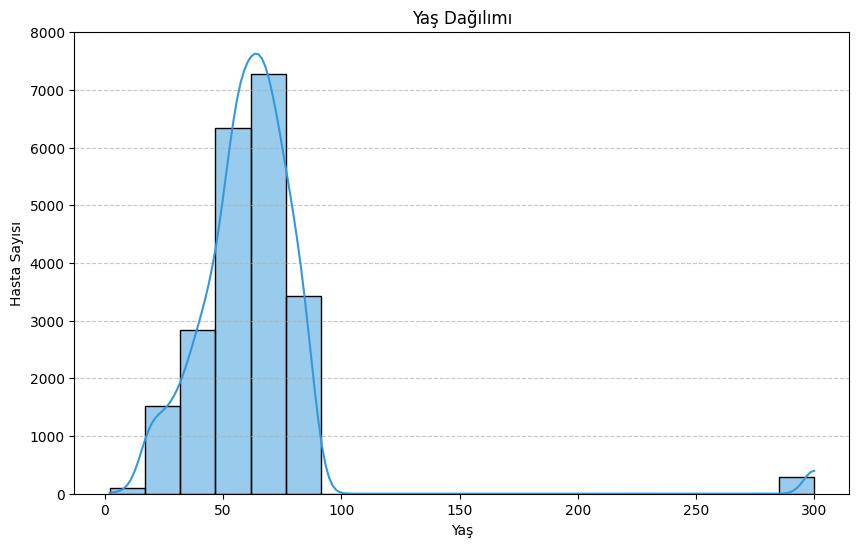

In [9]:
plt.figure(figsize=(10, 6))
sns.histplot(ptbxl_df['age'], bins=20, kde=True, color='#3498db')
plt.title('Yaş Dağılımı')
plt.xlabel('Yaş')
plt.ylabel('Hasta Sayısı')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 2. Cinsiyet Dağılımı (Gender Distribution)

Cinsiyet sütunu (sex) için: `0` kadın, `1` erkek olarak kabul edilmektedir.

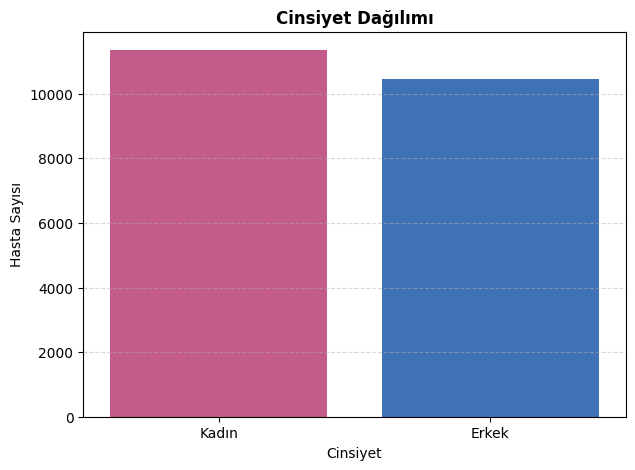

In [10]:
my_colors = ['#D44A8A', '#2B70C9']

plt.figure(figsize=(7, 5))
sns.countplot(x='sex', data=ptbxl_df, hue='sex', palette=my_colors, legend=False)

plt.title('Cinsiyet Dağılımı', fontsize=12, fontweight='bold')
plt.xlabel('Cinsiyet')
plt.ylabel('Hasta Sayısı')
plt.xticks([0, 1], ['Kadın', 'Erkek'])
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### 3. Stratifikasyon Katmanları Dağılımı (Stratification Folds Distribution)

/tmp/ipykernel_1472/3834341089.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='strat_fold', data=ptbxl_df, palette='magma')


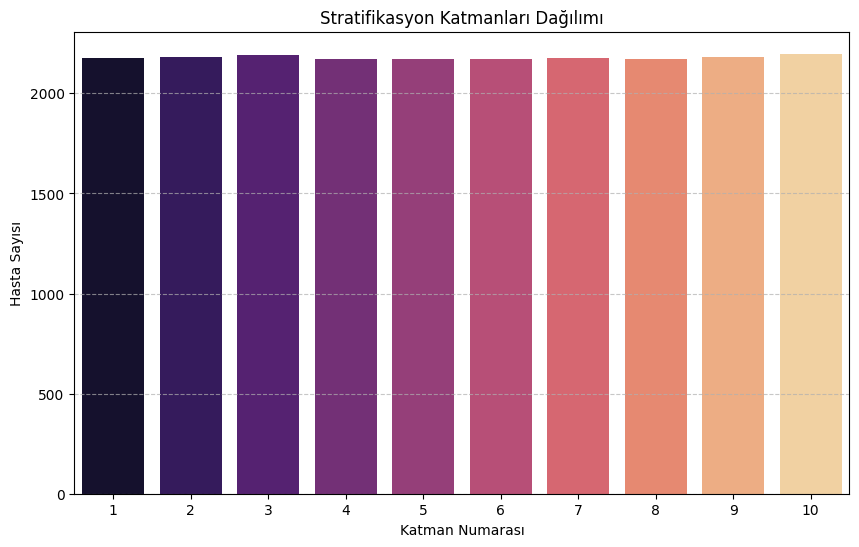

In [11]:
plt.figure(figsize=(10, 6))
sns.countplot(x='strat_fold', data=ptbxl_df, palette='magma')
plt.title('Stratifikasyon Katmanları Dağılımı')
plt.xlabel('Katman Numarası')
plt.ylabel('Hasta Sayısı')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 4. WFDB Kayıtlarını Ayıkla (Gerekirse)

ECG sinyallerini yüklemek için `records100.zip` dosyasının `data_path` altında açılmış olması gerekiyor. Eğer açılmadıysa, bu adım onu ayıklayacaktır.

In [12]:
zip_filepath = os.path.join(data_path, "records100.zip")
extract_path = data_path # records100 klasörünü data_path içine açar

# records100 klasörünün varlığını kontrol edelim
if not os.path.exists(os.path.join(extract_path, "records100")):
    if os.path.exists(zip_filepath):
        print(f"Ayıklanıyor: records100.zip...")
        with zipfile.ZipFile(zip_filepath, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
        print(f"Başarıyla ayıklandı: records100.zip")
    else:
        print(f"Hata: 'records100.zip' {data_path} konumunda bulunamadı. Lütfen dosyanın orada olduğundan emin olun.")
else:
    print(f"records100 klasörü zaten mevcut (ayıklama atlandı).")


records100 klasörü zaten mevcut (ayıklama atlandı).


### 5. Rastgele Bir EKG Kaydı Yükle ve Sinyal Detaylarını Görüntüle

In [13]:
# ptbxl_df'ten rastgele bir kayıt seçelim
sample_row = ptbxl_df.sample(1).iloc[0]

# wfdb.rdsamp'in beklediği formatta dosya yolunu oluşturalım
# filename_lr sütunu 'records100/xxxx/yyyy_lr' formatındadır
# wfdb bu yolu 'data_path/records100/xxxx/yyyy' olarak otomatik tamamlar
# Bu yüzden sadece 'filename_lr' içindeki yolu kullanıyoruz.

record_name = os.path.splitext(sample_row['filename_lr'])[0] # '.dat' veya '_lr' uzantısını kaldır
full_record_path = os.path.join(data_path, record_name) # data_path ile birleştir

print(f"Yüklenecek kayıt: {full_record_path}")

try:
    # wfdb ile sinyali (12 kanal) yüklüyoruz
    signals, fields = wfdb.rdsamp(full_record_path)

    # Sadece Lead I (0. indeks) kanalını ayırıyoruz
    lead_i_signal = signals[:, 0]

    print(f"✓ Hasta ID: {sample_row['patient_id']} için Lead I kanalı başarıyla yüklendi.")
    print(f"Sinyal Uzunluğu: {len(lead_i_signal)} örnek")
    print(f"Örnekleme Frekansı: {fields['fs']} Hz")
except Exception as e:
    print(f"Hata: Kayıt yüklenemedi - {e}")
    print("Lütfen 'records100' klasörünün `BeatKrypt` dizini altında doğru bir şekilde ayıklandığından emin olun.")


Yüklenecek kayıt: /content/drive/MyDrive/BeatKrypt/records100/06000/06671_lr
✓ Hasta ID: 21020 için Lead I kanalı başarıyla yüklendi.
Sinyal Uzunluğu: 1000 örnek
Örnekleme Frekansı: 100 Hz


### 6. Ham Sinyal Görselleştirme (İlk 5 Saniye)

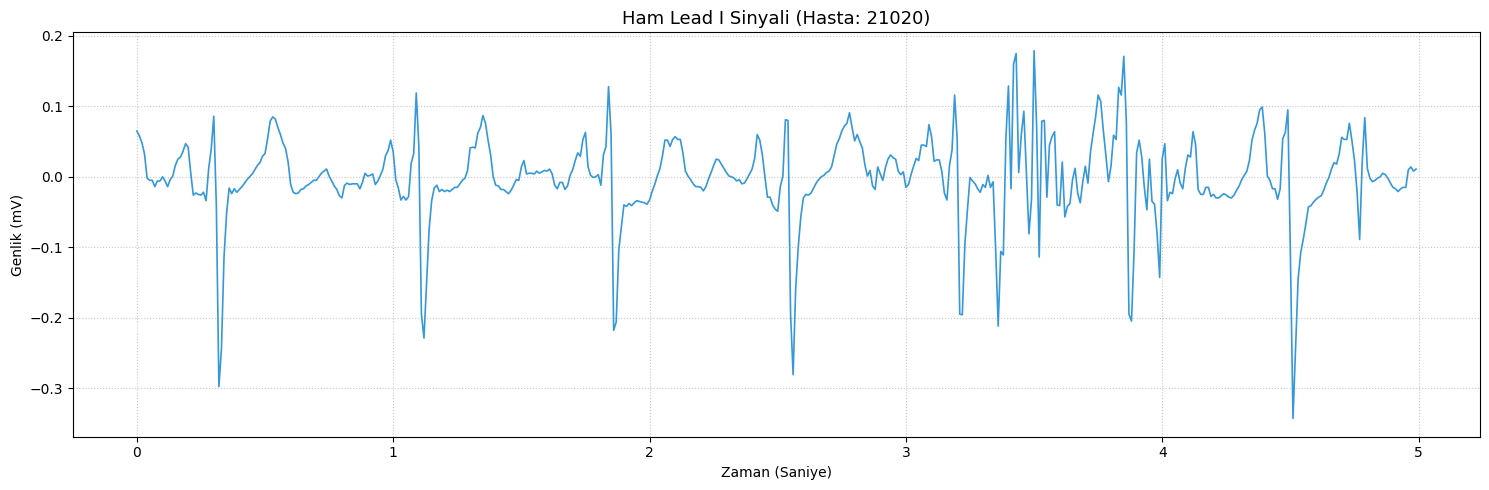

1. Adım tamamlandı. Sinyal normalse '2. adıma geçebiliriz' diyebilirsiniz.


In [14]:
# 100Hz frekansta 5 saniye = 500 örnek noktası
n_samples = 500
time_axis = np.arange(n_samples) / sample_rate

plt.figure(figsize=(15, 5))

# lead_i_signal'ın yeterli uzunlukta olduğundan emin olalım
if len(lead_i_signal) >= n_samples:
    plt.plot(time_axis, lead_i_signal[:n_samples], color='#3498db', linewidth=1.2)
    plt.title(f"Ham Lead I Sinyali (Hasta: {sample_row['patient_id']})", fontsize=13)
    plt.xlabel("Zaman (Saniye)")
    plt.ylabel("Genlik (mV)")
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print("1. Adım tamamlandı. Sinyal normalse '2. adıma geçebiliriz' diyebilirsiniz.")
else:
    print(f"Hata: Sinyal yeterince uzun değil ({len(lead_i_signal)} örnek). İlk {n_samples} örneği görüntüleyemiyoruz.")
    print("Daha kısa bir sinyal uzunluğu seçmeyi deneyebilir veya başka bir kayıt seçebilirsiniz.")


## 2. Adım: Sinyal İşleme ve Gürültü Azaltma (Filtering)

EKG sinyallerinde genellikle baseline wander (taban çizgisi kayması) ve yüksek frekanslı gürültü bulunur. Bu gürültüleri gidermek ve sinyalin daha net hale gelmesini sağlamak için bir **bandpass filtre** uygulayacağız. Bu sayede P, QRS, T dalgalarını daha iyi ayırt edebiliriz.

In [15]:
from scipy.signal import butter, lfilter

def butter_bandpass(lowcut, highcut, fs, order=5):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

# Filtre parametreleri
lowcut = 0.5 # Hz (Düşük kesim frekansı, baseline wander'ı azaltır)
highcut = 40.0 # Hz (Yüksek kesim frekansı, kas artefaktlarını ve yüksek frekanslı gürültüyü azaltır)
fs = sample_rate # Örnekleme frekansı (100 Hz olarak ayarlanmıştı)

# Ham sinyale filtreyi uygulayalım
filtered_lead_i_signal = butter_bandpass_filter(lead_i_signal, lowcut, highcut, fs, order=5)

print(f"✓ EKG sinyali başarıyla filtrelendi (Bandpass: {lowcut}-{highcut} Hz).")

✓ EKG sinyali başarıyla filtrelendi (Bandpass: 0.5-40.0 Hz).


### Filtrelenmiş ve Ham Sinyalin Karşılaştırılması

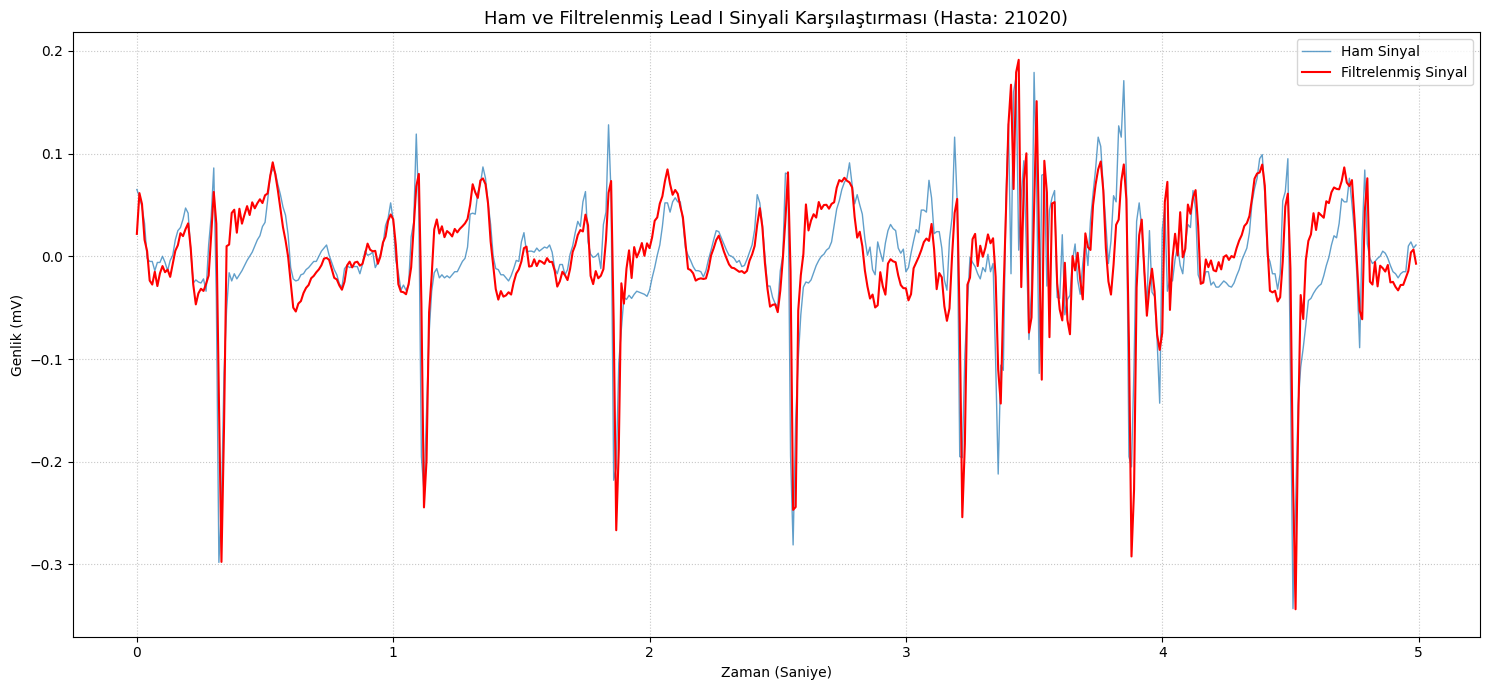

2. Adım tamamlandı. Filtreleme sonrası sinyal kalitesi hakkında ne düşünüyorsunuz?


In [16]:
plt.figure(figsize=(15, 7))

plt.plot(time_axis, lead_i_signal[:n_samples], label='Ham Sinyal', alpha=0.7, linewidth=1)
plt.plot(time_axis, filtered_lead_i_signal[:n_samples], label='Filtrelenmiş Sinyal', color='red', linewidth=1.5)

plt.title(f"Ham ve Filtrelenmiş Lead I Sinyali Karşılaştırması (Hasta: {sample_row['patient_id']})", fontsize=13)
plt.xlabel("Zaman (Saniye)")
plt.ylabel("Genlik (mV)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

print("2. Adım tamamlandı. Filtreleme sonrası sinyal kalitesi hakkında ne düşünüyorsunuz?")

## 3. Adım: R-Tepe Tespiti (R-Peak Detection)

EKG sinyalindeki R-tepelerinin tespiti, kalp atış hızı ve diğer ritim analizleri için temel bir adımdır. Pan-Tompkins algoritması, EKG sinyallerinde R-tepelerini güvenilir bir şekilde bulmak için yaygın olarak kullanılan bir yöntemdir. Bu adımda, filtrelenmiş sinyal üzerinde R-tepelerini tespit edeceğiz.

In [17]:

# NeuroKit2 kütüphanesini kullanarak R-tepe tespiti yapalım
# Bu fonksiyon Pan-Tompkins veya diğer popüler algoritmaları içerir.
# fs, örnekleme frekansıdır.

# R-tepe tespiti için NeuroKit2'nin "ecg_peaks" fonksiyonunu kullanıyoruz.
# Bu fonksiyon bize R-tepe indekslerini döndürecektir.

_, rpeaks = nk.ecg_peaks(filtered_lead_i_signal, sampling_rate=fs)

# 'ECG_R_Peaks' anahtarı altındaki R-tepe indekslerini alalım
r_peaks_indices = rpeaks['ECG_R_Peaks']

print(f"✓ {len(r_peaks_indices)} adet R-tepesi tespit edildi.")

✓ 14 adet R-tepesi tespit edildi.


### Tespit Edilen R-Tepelerinin Görselleştirilmesi

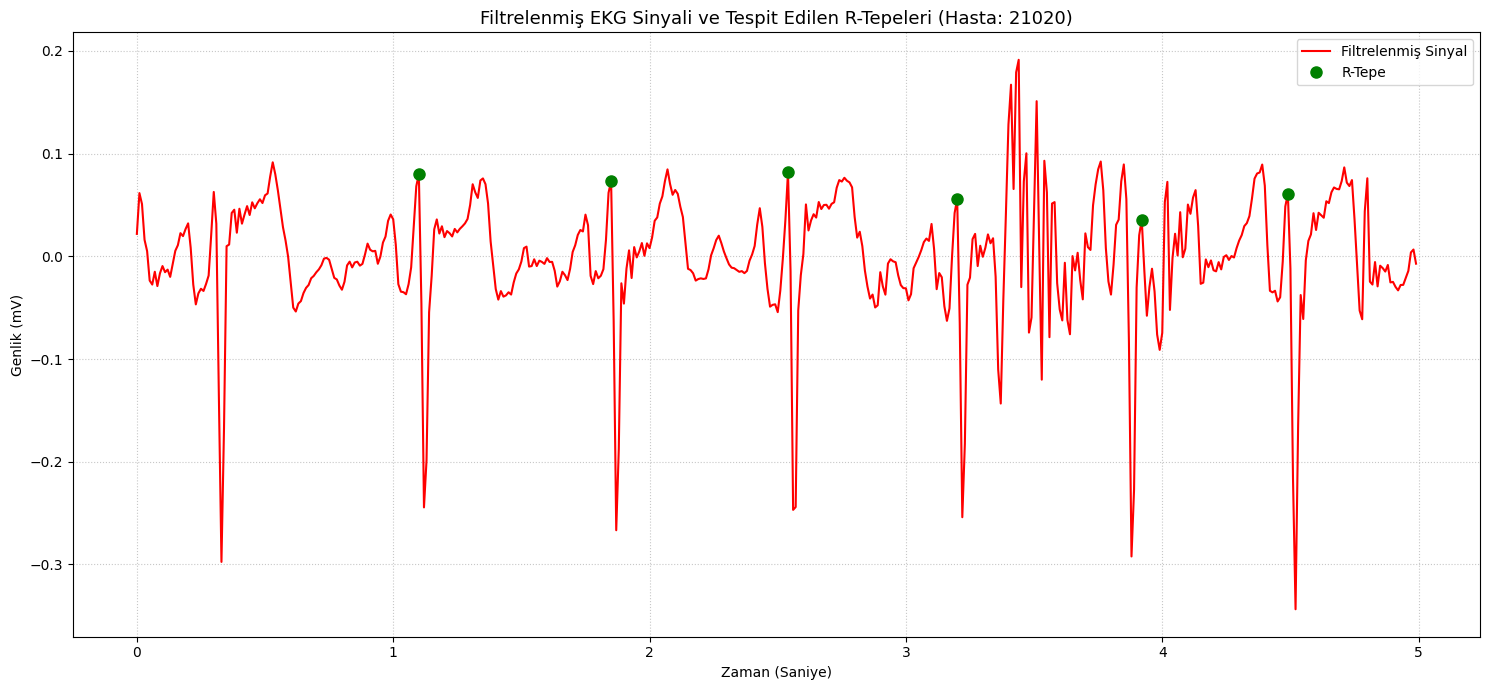

3. Adım tamamlandı. R-tepelerinin doğru tespit edildiğini düşünüyor musunuz?


In [18]:
plt.figure(figsize=(15, 7))

plt.plot(time_axis, filtered_lead_i_signal[:n_samples], color='red', linewidth=1.5, label='Filtrelenmiş Sinyal')

# Tespit edilen R-tepelerini işaretleyelim
# Sadece gösterilen zaman aralığındaki (ilk n_samples) R-tepelerini çizelim
r_peaks_in_view = [idx for idx in r_peaks_indices if idx < n_samples]
plt.plot(time_axis[r_peaks_in_view], filtered_lead_i_signal[r_peaks_in_view], 'o', color='green', markersize=8, label='R-Tepe')

plt.title(f"Filtrelenmiş EKG Sinyali ve Tespit Edilen R-Tepeleri (Hasta: {sample_row['patient_id']})", fontsize=13)
plt.xlabel("Zaman (Saniye)")
plt.ylabel("Genlik (mV)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

print("3. Adım tamamlandı. R-tepelerinin doğru tespit edildiğini düşünüyor musunuz?")

## 4. Adım: RR İntervalleri ve Kalp Atış Hızı Hesaplama

R-tepelerinin tespitiyle, ardışık R-tepeleri arasındaki zaman aralığını (RR intervalleri) ve bunlardan kalp atış hızını (HR) hesaplayabiliriz. Bu metrikler, kalp ritmi analizi için temel teşkil eder.

In [19]:
# RR intervallerini (örnek cinsinden) hesaplayalım
rr_intervals_samples = np.diff(r_peaks_indices)

# RR intervallerini saniye cinsine çevirelim
rr_intervals_seconds = rr_intervals_samples / fs

# Kalp atış hızını (BPM) hesaplayalım
# (60 saniye / RR interval saniye) * 1 atım
heart_rates_bpm = 60 / rr_intervals_seconds

print(f"Tespit edilen {len(rr_intervals_seconds)} adet RR intervali ve kalp atış hızı hesaplandı.")
print(f"Ortalama RR Intervali: {np.mean(rr_intervals_seconds):.2f} saniye")
print(f"Ortalama Kalp Atış Hızı: {np.mean(heart_rates_bpm):.2f} BPM")

Tespit edilen 13 adet RR intervali ve kalp atış hızı hesaplandı.
Ortalama RR Intervali: 0.67 saniye
Ortalama Kalp Atış Hızı: 90.31 BPM


### RR İntervalleri Dağılımı

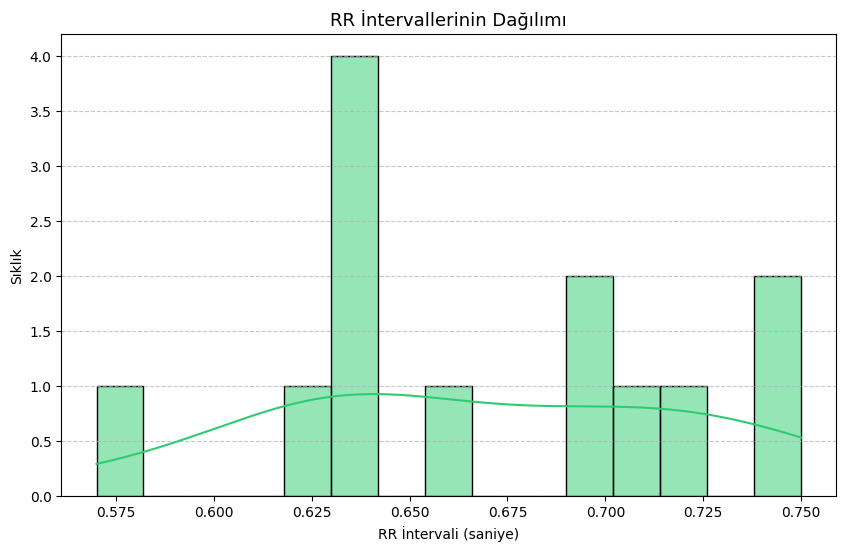

In [20]:
plt.figure(figsize=(10, 6))
sns.histplot(rr_intervals_seconds, kde=True, color='#2ecc71', bins=15)
plt.title('RR İntervallerinin Dağılımı', fontsize=13)
plt.xlabel('RR İntervali (saniye)')
plt.ylabel('Sıklık')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Kalp Atış Hızı (BPM) Dağılımı

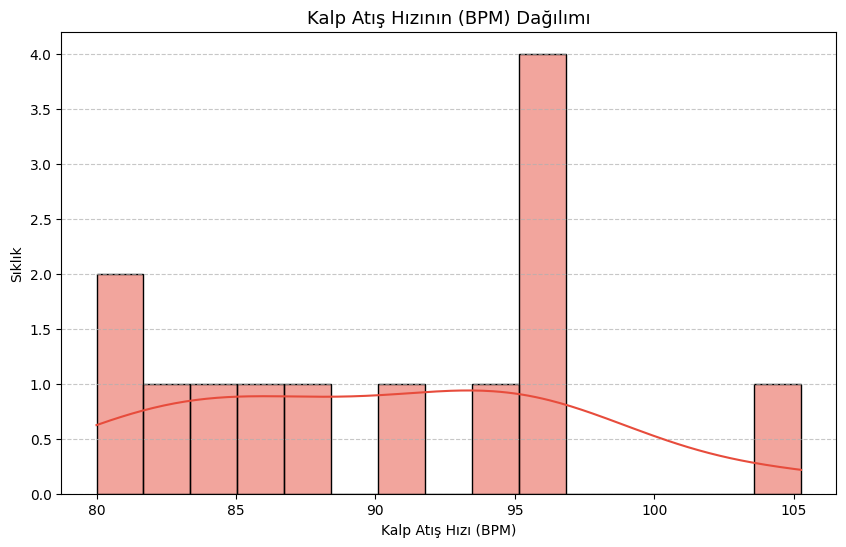

In [21]:
plt.figure(figsize=(10, 6))
sns.histplot(heart_rates_bpm, kde=True, color='#e74c3c', bins=15)
plt.title('Kalp Atış Hızının (BPM) Dağılımı', fontsize=13)
plt.xlabel('Kalp Atış Hızı (BPM)')
plt.ylabel('Sıklık')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

✓ Toplam 12 adet tekil kalp atışı (P-Q-R-S-T) cımbızlandı.


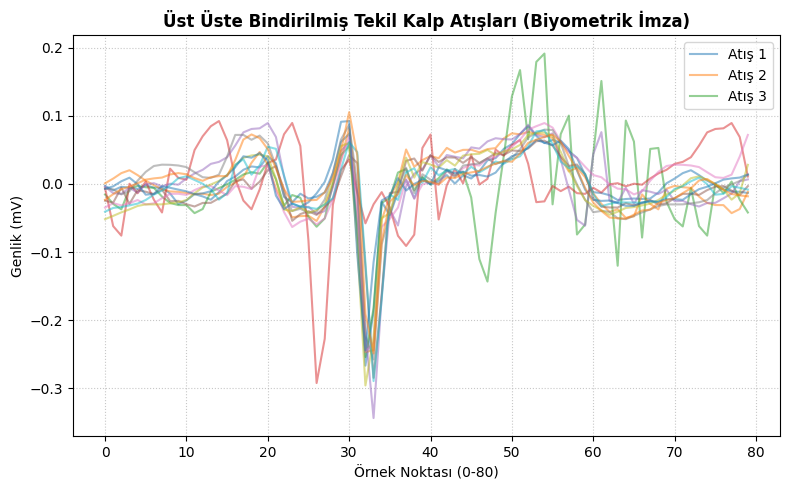

In [22]:
# R zirvelerinin etrafından dinamik kırpma yapalım (Histogramınızla uyumlu: 80 örnek = 0.8 sn)
left_margin = 30
right_margin = 50

single_beats = []

# Sinyal sınırlarının dışına taşmamak için ilk ve son R tepelerini atlayarak dönüyoruz
for peak in r_peaks_indices[1:-1]:
    start = peak - left_margin
    end = peak + right_margin

    # Kesilen kalp atışı parçasını al
    beat = filtered_lead_i_signal[start:end]

    # Sadece tam boyuttaki pencereleri kabul et
    if len(beat) == (left_margin + right_margin):
        single_beats.append(beat)

print(f"✓ Toplam {len(single_beats)} adet tekil kalp atışı (P-Q-R-S-T) cımbızlandı.")

# Bölünen tüm kalp atışlarını üst üste çizdirerek morfolojik tutarlılığı kontrol edelim
plt.figure(figsize=(8, 5))
for i, beat in enumerate(single_beats):
    plt.plot(beat, alpha=0.5, label=f"Atış {i+1}" if i < 3 else "")

plt.title("Üst Üste Bindirilmiş Tekil Kalp Atışları (Biyometrik İmza)", fontsize=12, fontweight='bold')
plt.xlabel("Örnek Noktası (0-80)")
plt.ylabel("Genlik (mV)")
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Problem: Kesilen EKG pencerelerindeki R-dalgaları dikey eksende aynı hizada değildir.

Risk: Modelin morfolojiyi öğrenememesi ve kaymaları yanlış bir özellik (feature) olarak algılaması.

Çözüm: İndeks senkronizasyonu güncellenerek tüm kalp atışları tam orta noktada (30. örnek) kilitlenmiş ve normalize edilmiştir.

✓ Mükemmel hizalanmış ve normalize edilmiş 12 adet kalp atışı hazır!


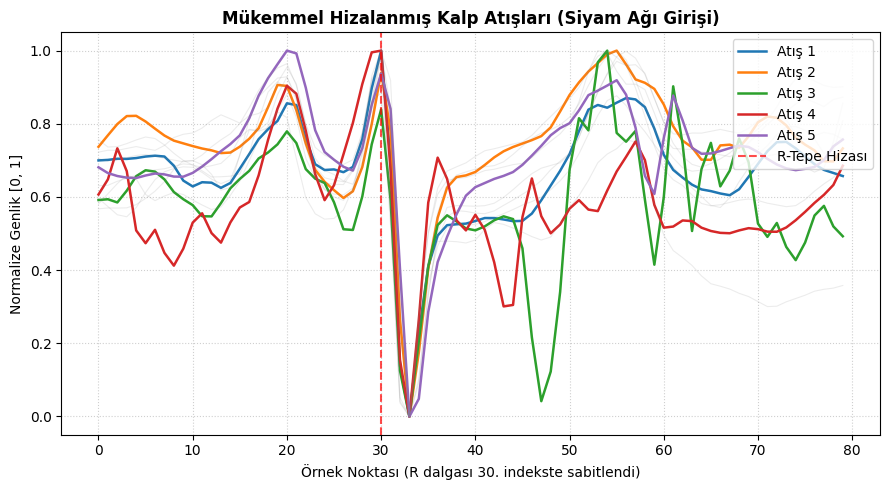

In [23]:
# 1. Sinyali NeuroKit'in yerleşik algoritmasıyla temizleyip tepeleri sağlama alalım
# Örnekleme frekansı (sample_rate) yukarıdaki hücrelerde 100 olarak tanımlanmıştı.
ecg_cleaned = nk.ecg_clean(lead_i_signal, sampling_rate=sample_rate, method="neurokit")
_, peaks = nk.ecg_peaks(ecg_cleaned, sampling_rate=sample_rate)
r_peaks_exact = peaks["ECG_R_Peaks"]

# 2. Ortalama pencere genişlikleri (Histogramınla tam uyumlu: 30 sol + 50 sağ = 80 örnek)
left_margin = 30
right_margin = 50

aligned_beats = []

# Sınır taşmalarını engellemek için ilk ve son zirveyi atlayarak dönüyoruz
for peak in r_peaks_exact[1:-1]:
    start = peak - left_margin
    end = peak + right_margin

    # Sinyal sınırları içindeyse kes
    if start >= 0 and end <= len(ecg_cleaned):
        beat = ecg_cleaned[start:end]

        # Siyam Ağı (Siamese Network) için kritik adım:
        # Her atışı kendi içinde [0, 1] arasına normalize edelim (Genlik kaymalarını yok eder)
        beat_min = np.min(beat)
        beat_max = np.max(beat)
        if beat_max > beat_min:
            normalized_beat = (beat - beat_min) / (beat_max - beat_min)
            aligned_beats.append(normalized_beat)

print(f"✓ Mükemmel hizalanmış ve normalize edilmiş {len(aligned_beats)} adet kalp atışı hazır!")

# 3. Grafik Çizdirme: Şimdi jilet gibi üst üste binmeleri gerekiyor
plt.figure(figsize=(9, 5))
for i, beat in enumerate(aligned_beats):
    if i < 5:
        plt.plot(beat, label=f"Atış {i+1}", linewidth=1.8)
    else:
        plt.plot(beat, color='gray', alpha=0.15, linewidth=0.8)

# Tam 30. noktada dikey bir kılavuz çizgisi çekelim (R dalgası hizası)
plt.axvline(x=left_margin, color='red', linestyle='--', alpha=0.7, label='R-Tepe Hizası')

plt.title("Mükemmel Hizalanmış Kalp Atışları (Siyam Ağı Girişi)", fontsize=12, fontweight='bold')
plt.xlabel("Örnek Noktası (R dalgası 30. indekste sabitlendi)")
plt.ylabel("Normalize Genlik [0, 1]")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

🚀 4x2 panel için 16 farklı hasta rastgele seçiliyor ve hizalanıyor...


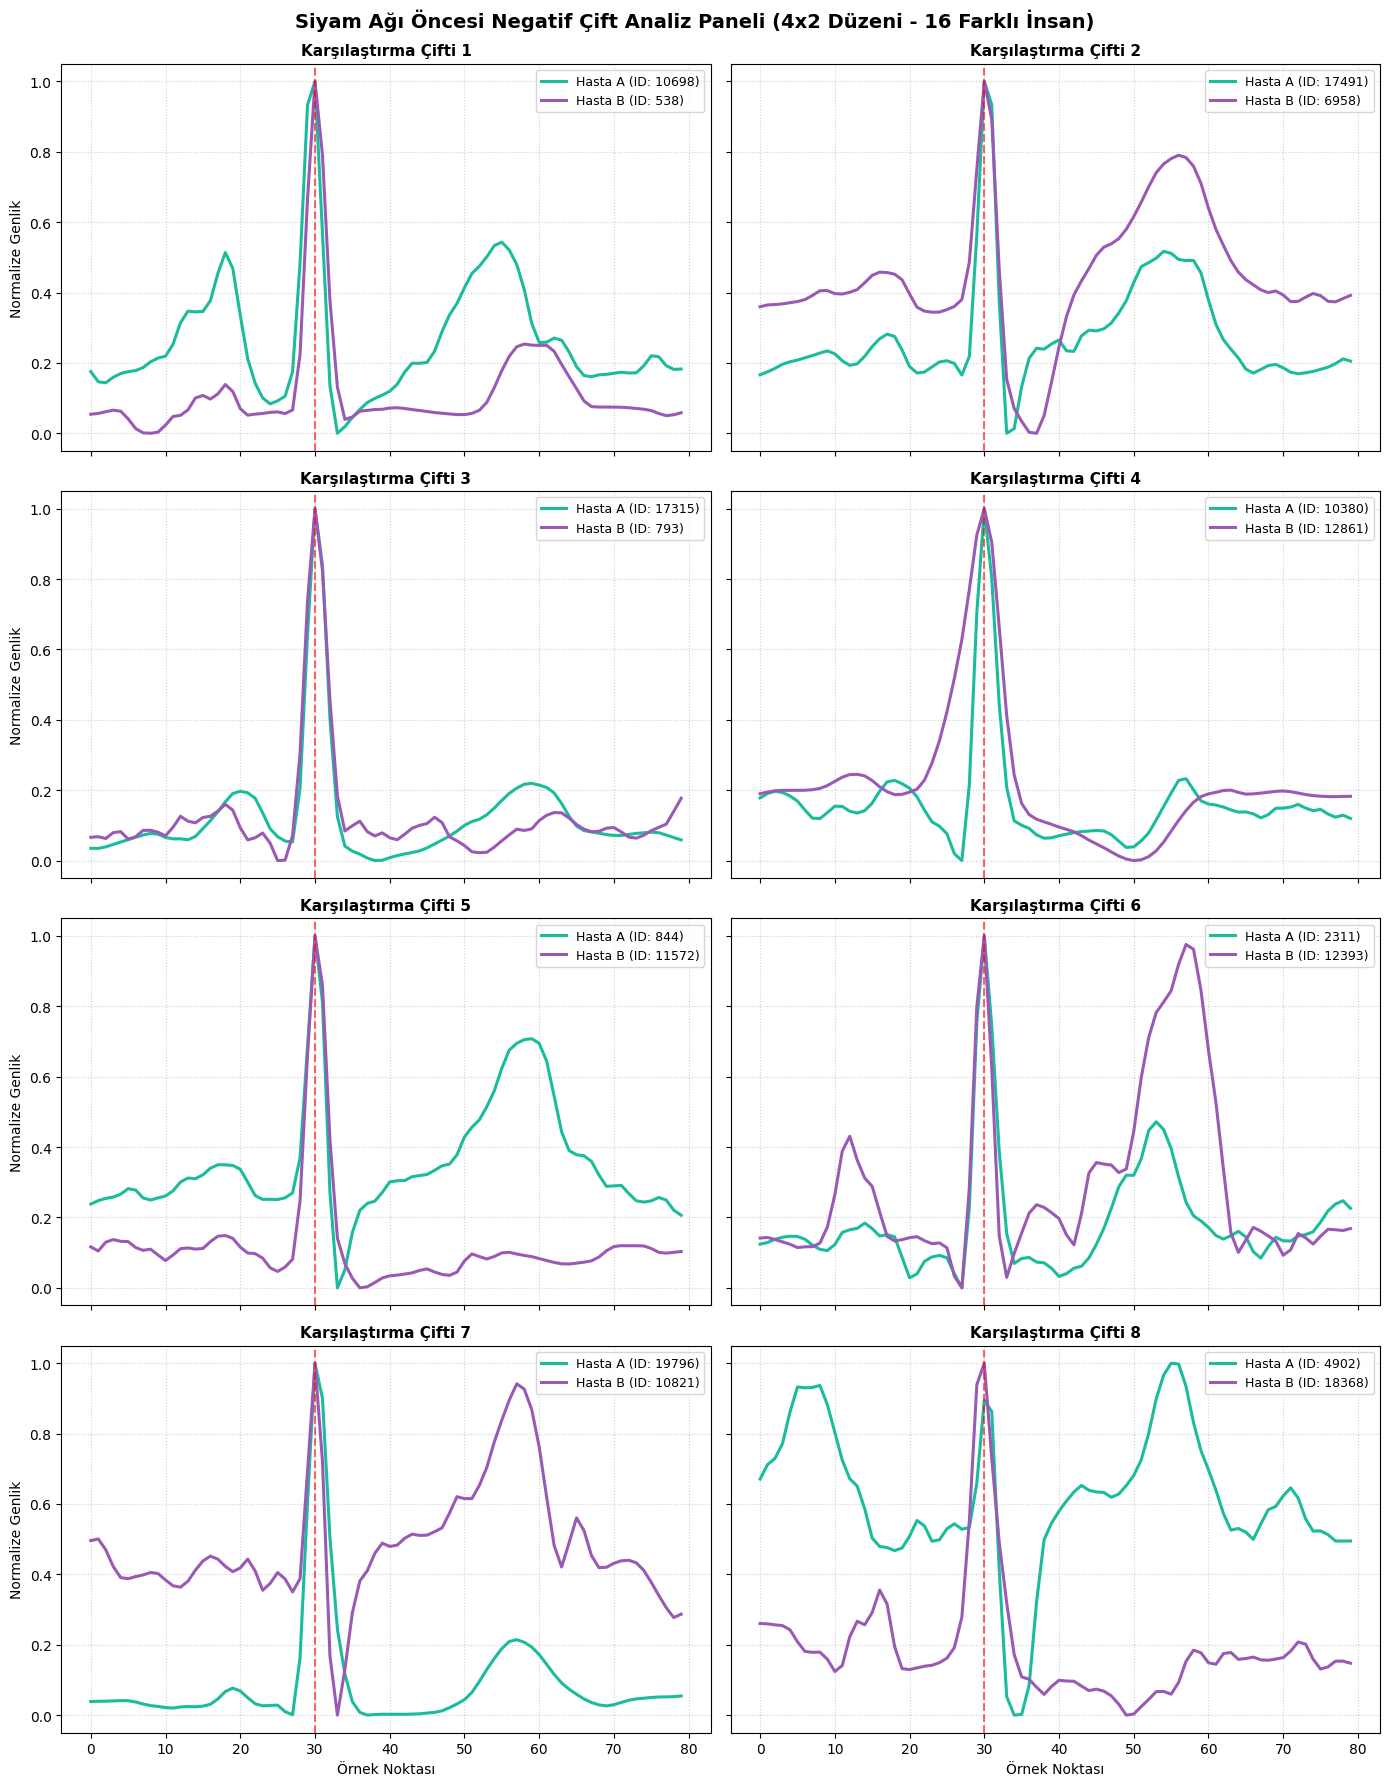

✓ 4x2 boyutundaki dikey panel başarıyla oluşturuldu!


In [24]:
def get_aligned_beat_fixed(record_path):
    """Verilen dosya yolundan ilk temiz ve hizalanmış kalp atışını döner."""
    try:
        signals, fields = wfdb.rdsamp(record_path)
        sig = signals[:, 0] # Lead I kanalı

        # NeuroKit ile temizleme ve R-tepe tespiti (fs = 100 Hz)
        clean_sig = nk.ecg_clean(sig, sampling_rate=100, method="neurokit")
        _, peaks = nk.ecg_peaks(clean_sig, sampling_rate=100)
        r_peaks = peaks["ECG_R_Peaks"]

        # İlk kararlı tepeyi alıp (30 sol, 50 sağ) keselim
        if len(r_peaks) > 1:
            peak = r_peaks[1]
            start = peak - 30
            end = peak + 50
            if start >= 0 and end <= len(clean_sig):
                beat = clean_sig[start:end]
                # [0, 1] Normalizasyonu (Genlik dengelemesi)
                return (beat - np.min(beat)) / (np.max(beat) - np.min(beat))
    except Exception as e:
        pass
    return None

# 4 satır, 2 sütun toplam 8 grafiklik (4x2) figür alanı
fig, axes = plt.subplots(4, 2, figsize=(14, 18), sharex=True, sharey=True)
axes = axes.flatten() # 2D matrisi 1D listeye düzleştiriyoruz

print("🚀 4x2 panel için 16 farklı hasta rastgele seçiliyor ve hizalanıyor...")

# Çakışmaları önlemek için tekil hastaları önceden filtreleyelim
unique_patients = ptbxl_df.drop_duplicates(subset=['patient_id'])

for i in range(8):
    # Her alt grafik için 2 farklı hasta seçelim
    sample_patients = unique_patients.sample(2)

    id_a = sample_patients.iloc[0]['patient_id']
    path_a = os.path.join(data_path, os.path.splitext(sample_patients.iloc[0]['filename_lr'])[0])

    id_b = sample_patients.iloc[1]['patient_id']
    path_b = os.path.join(data_path, os.path.splitext(sample_patients.iloc[1]['filename_lr'])[0])

    beat_a = get_aligned_beat_fixed(path_a)
    beat_b = get_aligned_beat_fixed(path_b)

    ax = axes[i]

    if beat_a is not None and beat_b is not None:
        # İki farklı hastanın elektriksel imzasını çizelim
        ax.plot(beat_a, color='#1ABC9C', linewidth=2.2, label=f"Hasta A (ID: {id_a})") # Turkuaz
        ax.plot(beat_b, color='#9B59B6', linewidth=2.2, label=f"Hasta B (ID: {id_b})") # Mor

        # 30. örnek noktasındaki R-tepe hizalama çizgisi
        ax.axvline(x=30, color='red', linestyle='--', alpha=0.6)

        ax.set_title(f"Karşılaştırma Çifti {i+1}", fontsize=11, fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(loc='upper right', fontsize=9)
    else:
        ax.text(0.5, 0.5, "Sinyal Okuma Hatası", color="red", ha="center", va="center")

# Eksen etiketlerini dikey düzene (4x2) göre optimize edelim
for j in range(2):
    axes[j+6].set_xlabel("Örnek Noktası")
for k in range(4):
    axes[k*2].set_ylabel("Normalize Genlik")

plt.suptitle("Siyam Ağı Öncesi Negatif Çift Analiz Paneli (4x2 Düzeni - 16 Farklı İnsan)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

print("✓ 4x2 boyutundaki dikey panel başarıyla oluşturuldu!")

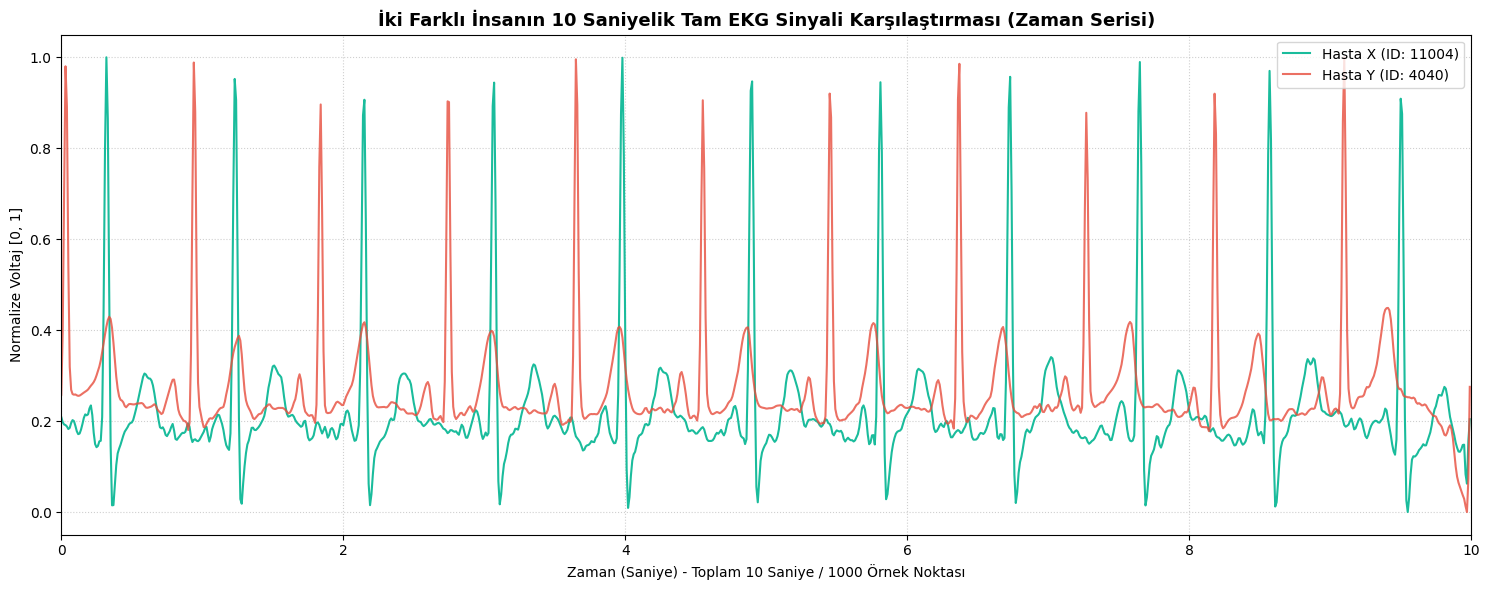

✓ 10 saniyelik tam zaman serisi karşılaştırma grafiği başarıyla oluşturuldu!


In [25]:
# 1. Veri setinden yine tamamen rastgele 2 farklı hasta seçelim
unique_patients = ptbxl_df.drop_duplicates(subset=['patient_id'])
sample_patients_long = unique_patients.sample(2)

# Hasta 1 Uzun Sinyal Bilgileri
id_long_a = sample_patients_long.iloc[0]['patient_id']
path_long_a = os.path.join(data_path, os.path.splitext(sample_patients_long.iloc[0]['filename_lr'])[0])

# Hasta 2 Uzun Sinyal Bilgileri
id_long_b = sample_patients_long.iloc[1]['patient_id']
path_long_b = os.path.join(data_path, os.path.splitext(sample_patients_long.iloc[1]['filename_lr'])[0])

def get_full_10s_signal(record_path):
    """Verilen dosya yolundan 10 saniyelik tam filtrelenmiş ve normalize edilmiş sinyali döner."""
    try:
        signals, fields = wfdb.rdsamp(record_path)
        sig = signals[:, 0] # Lead I kanalı (1000 örnek = 10 saniye)

        # Sinyali parazitlerden ve solunum dalgalanmalarından temizle
        clean_sig = nk.ecg_clean(sig, sampling_rate=100, method="neurokit")

        # Grafiklerin üst üste tam oturması için tüm 10 saniyelik sinyali [0, 1] arasına normalize et
        return (clean_sig - np.min(clean_sig)) / (np.max(clean_sig) - np.min(clean_sig))
    except Exception as e:
        return None

# İki hastanın da 10 saniyelik tam sinyalini çekelim
full_sig_a = get_full_10s_signal(path_long_a)
full_sig_b = get_full_10s_signal(path_long_b)

# 2. Grafik Çizdirme (10 Saniyelik Tam Karşılaştırma)
if full_sig_a is not None and full_sig_b is not None:
    # 100 Hz frekansta 1000 örnek = 10 saniye
    time_axis_10s = np.arange(len(full_sig_a)) / 100.0

    plt.figure(figsize=(15, 6))

    # İki uzun sinyali üst üste bindiriyoruz
    plt.plot(time_axis_10s, full_sig_a, color='#1ABC9C', linewidth=1.5, label=f"Hasta X (ID: {id_long_a})")
    plt.plot(time_axis_10s, full_sig_b, color='#E74C3C', linewidth=1.5, alpha=0.8, label=f"Hasta Y (ID: {id_long_b})")

    plt.title("İki Farklı İnsanın 10 Saniyelik Tam EKG Sinyali Karşılaştırması (Zaman Serisi)", fontsize=13, fontweight='bold')
    plt.xlabel("Zaman (Saniye) - Toplam 10 Saniye / 1000 Örnek Noktası")
    plt.ylabel("Normalize Voltaj [0, 1]")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper right')
    plt.xlim(0, 10) # 10 saniyelik tam pencereyi göster
    plt.tight_layout()
    plt.show()

    print("✓ 10 saniyelik tam zaman serisi karşılaştırma grafiği başarıyla oluşturuldu!")
else:
    print("Sinyal yüklenirken bir hata oluştu, lütfen hücreyi tekrar çalıştırın.")

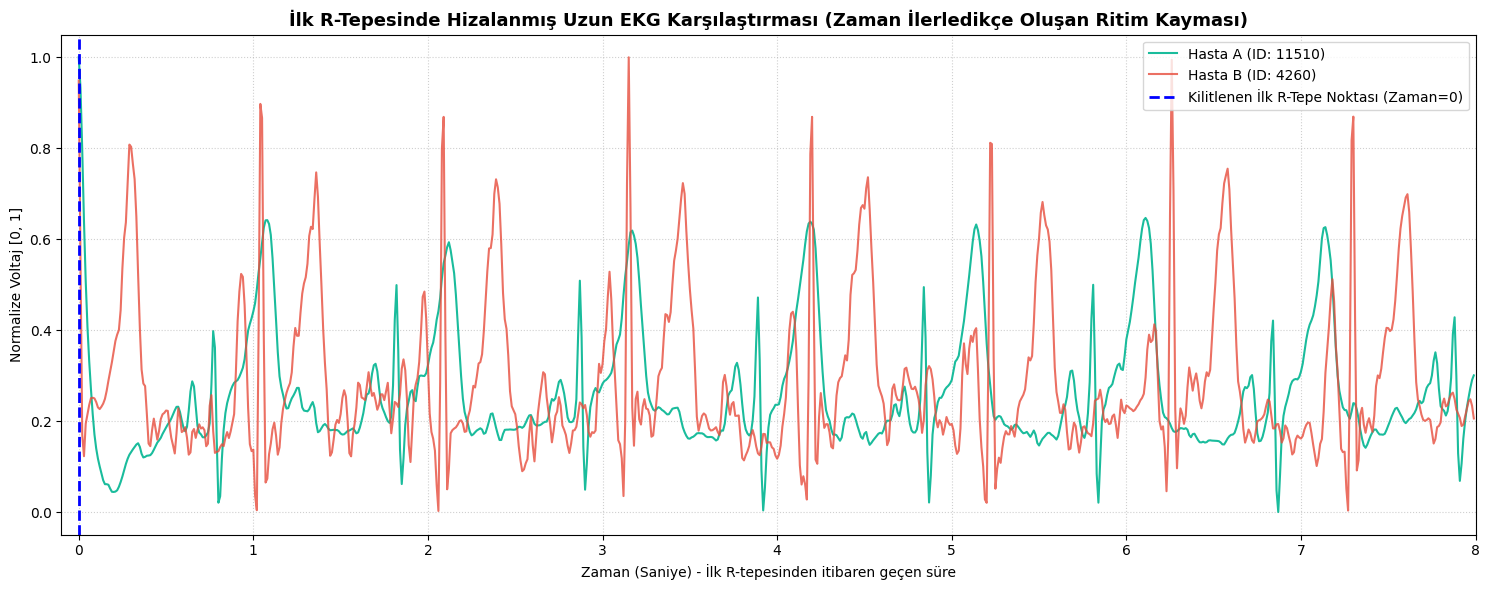

✓ İlk R-tepesine göre kilitlenmiş uzun zaman serisi grafiği başarıyla oluşturuldu!


In [26]:

# 1. Yine tamamen rastgele 2 farklı hasta seçelim
unique_patients = ptbxl_df.drop_duplicates(subset=['patient_id'])
sample_patients_sync = unique_patients.sample(2)

id_sync_a = sample_patients_sync.iloc[0]['patient_id']
path_sync_a = os.path.join(data_path, os.path.splitext(sample_patients_sync.iloc[0]['filename_lr'])[0])

id_sync_b = sample_patients_sync.iloc[1]['patient_id']
path_sync_b = os.path.join(data_path, os.path.splitext(sample_patients_sync.iloc[1]['filename_lr'])[0])

def get_aligned_long_signal(record_path):
    """Sinyalin ilk robust R-tepesini bulur ve sinyali o tepeden itibaren keserek döndürür."""
    try:
        signals, fields = wfdb.rdsamp(record_path)
        sig = signals[:, 0]

        # Filtreleme
        clean_sig = nk.ecg_clean(sig, sampling_rate=100, method="neurokit")

        # R-tepelerini bul
        _, peaks = nk.ecg_peaks(clean_sig, sampling_rate=100)
        r_peaks = peaks["ECG_R_Peaks"]

        # İlk kararlı R-tepesinin indeksini alalım
        first_robust_peak = r_peaks[0] if r_peaks[0] > 10 else r_peaks[1]

        # Sinyali bu ilk R-tepesinden itibaren keselim (Böylece iki sinyal de R-tepesiyle başlayacak)
        cropped_sig = clean_sig[first_robust_peak:]

        # Karşılaştırma için genliği [0, 1] arasına normalize et
        return (cropped_sig - np.min(cropped_sig)) / (np.max(cropped_sig) - np.min(cropped_sig))
    except Exception as e:
        return None

# İki hastanın sinyalini de ilk R-tepelerinden hizalayarak keselim
sync_sig_a = get_aligned_long_signal(path_sync_a)
sync_sig_b = get_aligned_long_signal(path_sync_b)

if sync_sig_a is not None and sync_sig_b is not None:
    # İki kesilmiş sinyalin de ortak min uzunluğunu bulalım (Grafiğin taşmaması için)
    min_len = min(len(sync_sig_a), len(sync_sig_b), 800) # Yaklaşık 8 saniyelik veri

    final_sig_a = sync_sig_a[:min_len]
    final_sig_b = sync_sig_b[:min_len]

    time_axis_sync = np.arange(min_len) / 100.0 # 100 Hz zaman ekseni

    plt.figure(figsize=(15, 6))

    # Sinyalleri çizdiriyoruz
    plt.plot(time_axis_sync, final_sig_a, color='#1ABC9C', linewidth=1.5, label=f"Hasta A (ID: {id_sync_a})")
    plt.plot(time_axis_sync, final_sig_b, color='#E74C3C', linewidth=1.5, alpha=0.8, label=f"Hasta B (ID: {id_sync_b})")

    # Hizalama noktasını (0. saniyeyi) işaretleyelim
    plt.axvline(x=0, color='blue', linestyle='--', linewidth=2, label='Kilitlenen İlk R-Tepe Noktası (Zaman=0)')

    plt.title("İlk R-Tepesinde Hizalanmış Uzun EKG Karşılaştırması (Zaman İlerledikçe Oluşan Ritim Kayması)", fontsize=13, fontweight='bold')
    plt.xlabel("Zaman (Saniye) - İlk R-tepesinden itibaren geçen süre")
    plt.ylabel("Normalize Voltaj [0, 1]")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper right')
    plt.xlim(-0.1, min_len/100.0)
    plt.tight_layout()
    plt.show()

    print("✓ İlk R-tepesine göre kilitlenmiş uzun zaman serisi grafiği başarıyla oluşturuldu!")
else:
    print("Sinyaller işlenirken bir hata oluştu, lütfen hücreyi tekrar çalıştırın.")

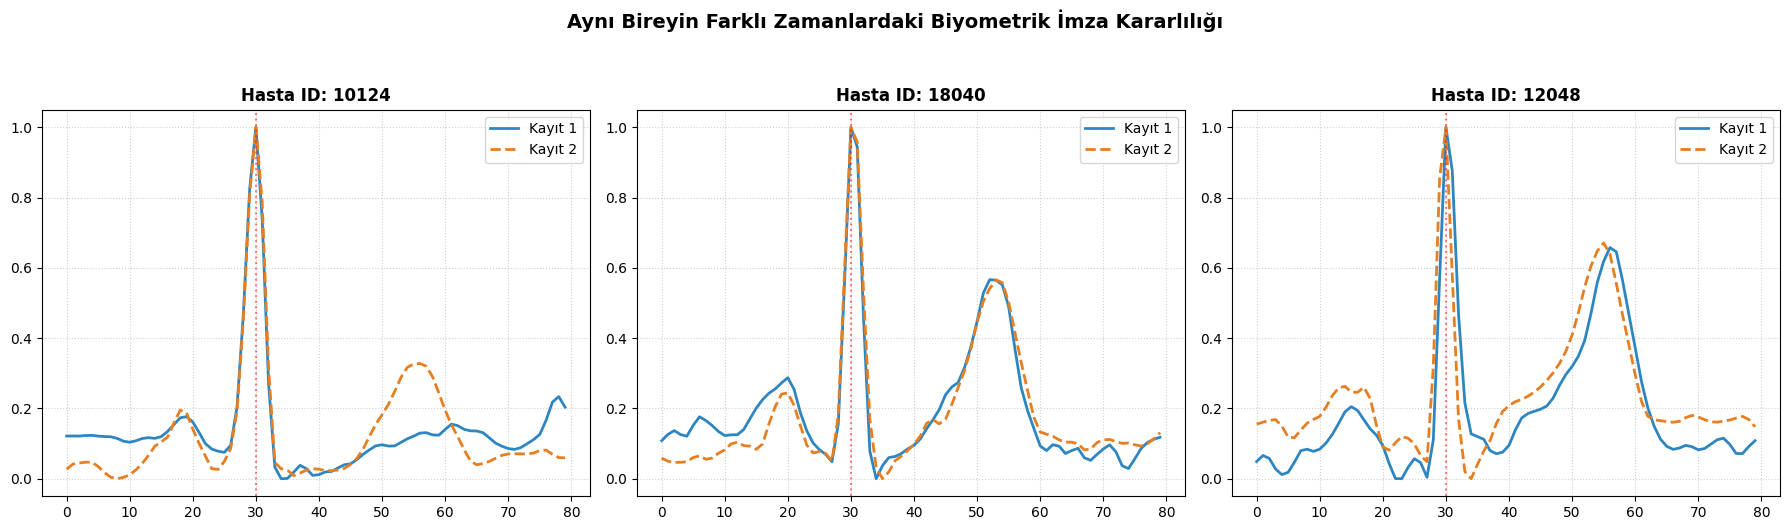

In [27]:
# 1. Aynı hastadan birden fazla kaydı olan hastaları bulalım
# PTB-XL veri setinde 'patient_id' sütunundaki tekrarlar aynı hastanın farklı kayıtlarıdır
patient_counts = ptbxl_df['patient_id'].value_counts()
multi_record_patients = patient_counts[patient_counts > 1].index.tolist()

# 2. Rastgele 3 hasta seçelim (her biri için 2 farklı kayıt)
sample_patients_id = np.random.choice(multi_record_patients, 3, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

for i, p_id in enumerate(sample_patients_id):
    # Bu hastanın kayıtlarını çek
    patient_records = ptbxl_df[ptbxl_df['patient_id'] == p_id].sample(2)

    path_1 = os.path.join(data_path, os.path.splitext(patient_records.iloc[0]['filename_lr'])[0])
    path_2 = os.path.join(data_path, os.path.splitext(patient_records.iloc[1]['filename_lr'])[0])

    # Her iki kayıttan da 1'er tane hizalı kalp atışı al
    beat_1 = get_aligned_beat_fixed(path_1) # Önceki hücrelerdeki fonksiyonu kullanıyoruz
    beat_2 = get_aligned_beat_fixed(path_2)

    ax = axes[i]
    if beat_1 is not None and beat_2 is not None:
        ax.plot(beat_1, color='#2E86C1', linewidth=2, label="Kayıt 1")
        ax.plot(beat_2, color='#E67E22', linewidth=2, linestyle='--', label="Kayıt 2")
        ax.axvline(x=30, color='red', linestyle=':', alpha=0.5)

        ax.set_title(f"Hasta ID: {p_id}", fontsize=12, fontweight='bold')
        ax.legend()
        ax.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Aynı Bireyin Farklı Zamanlardaki Biyometrik İmza Kararlılığı", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

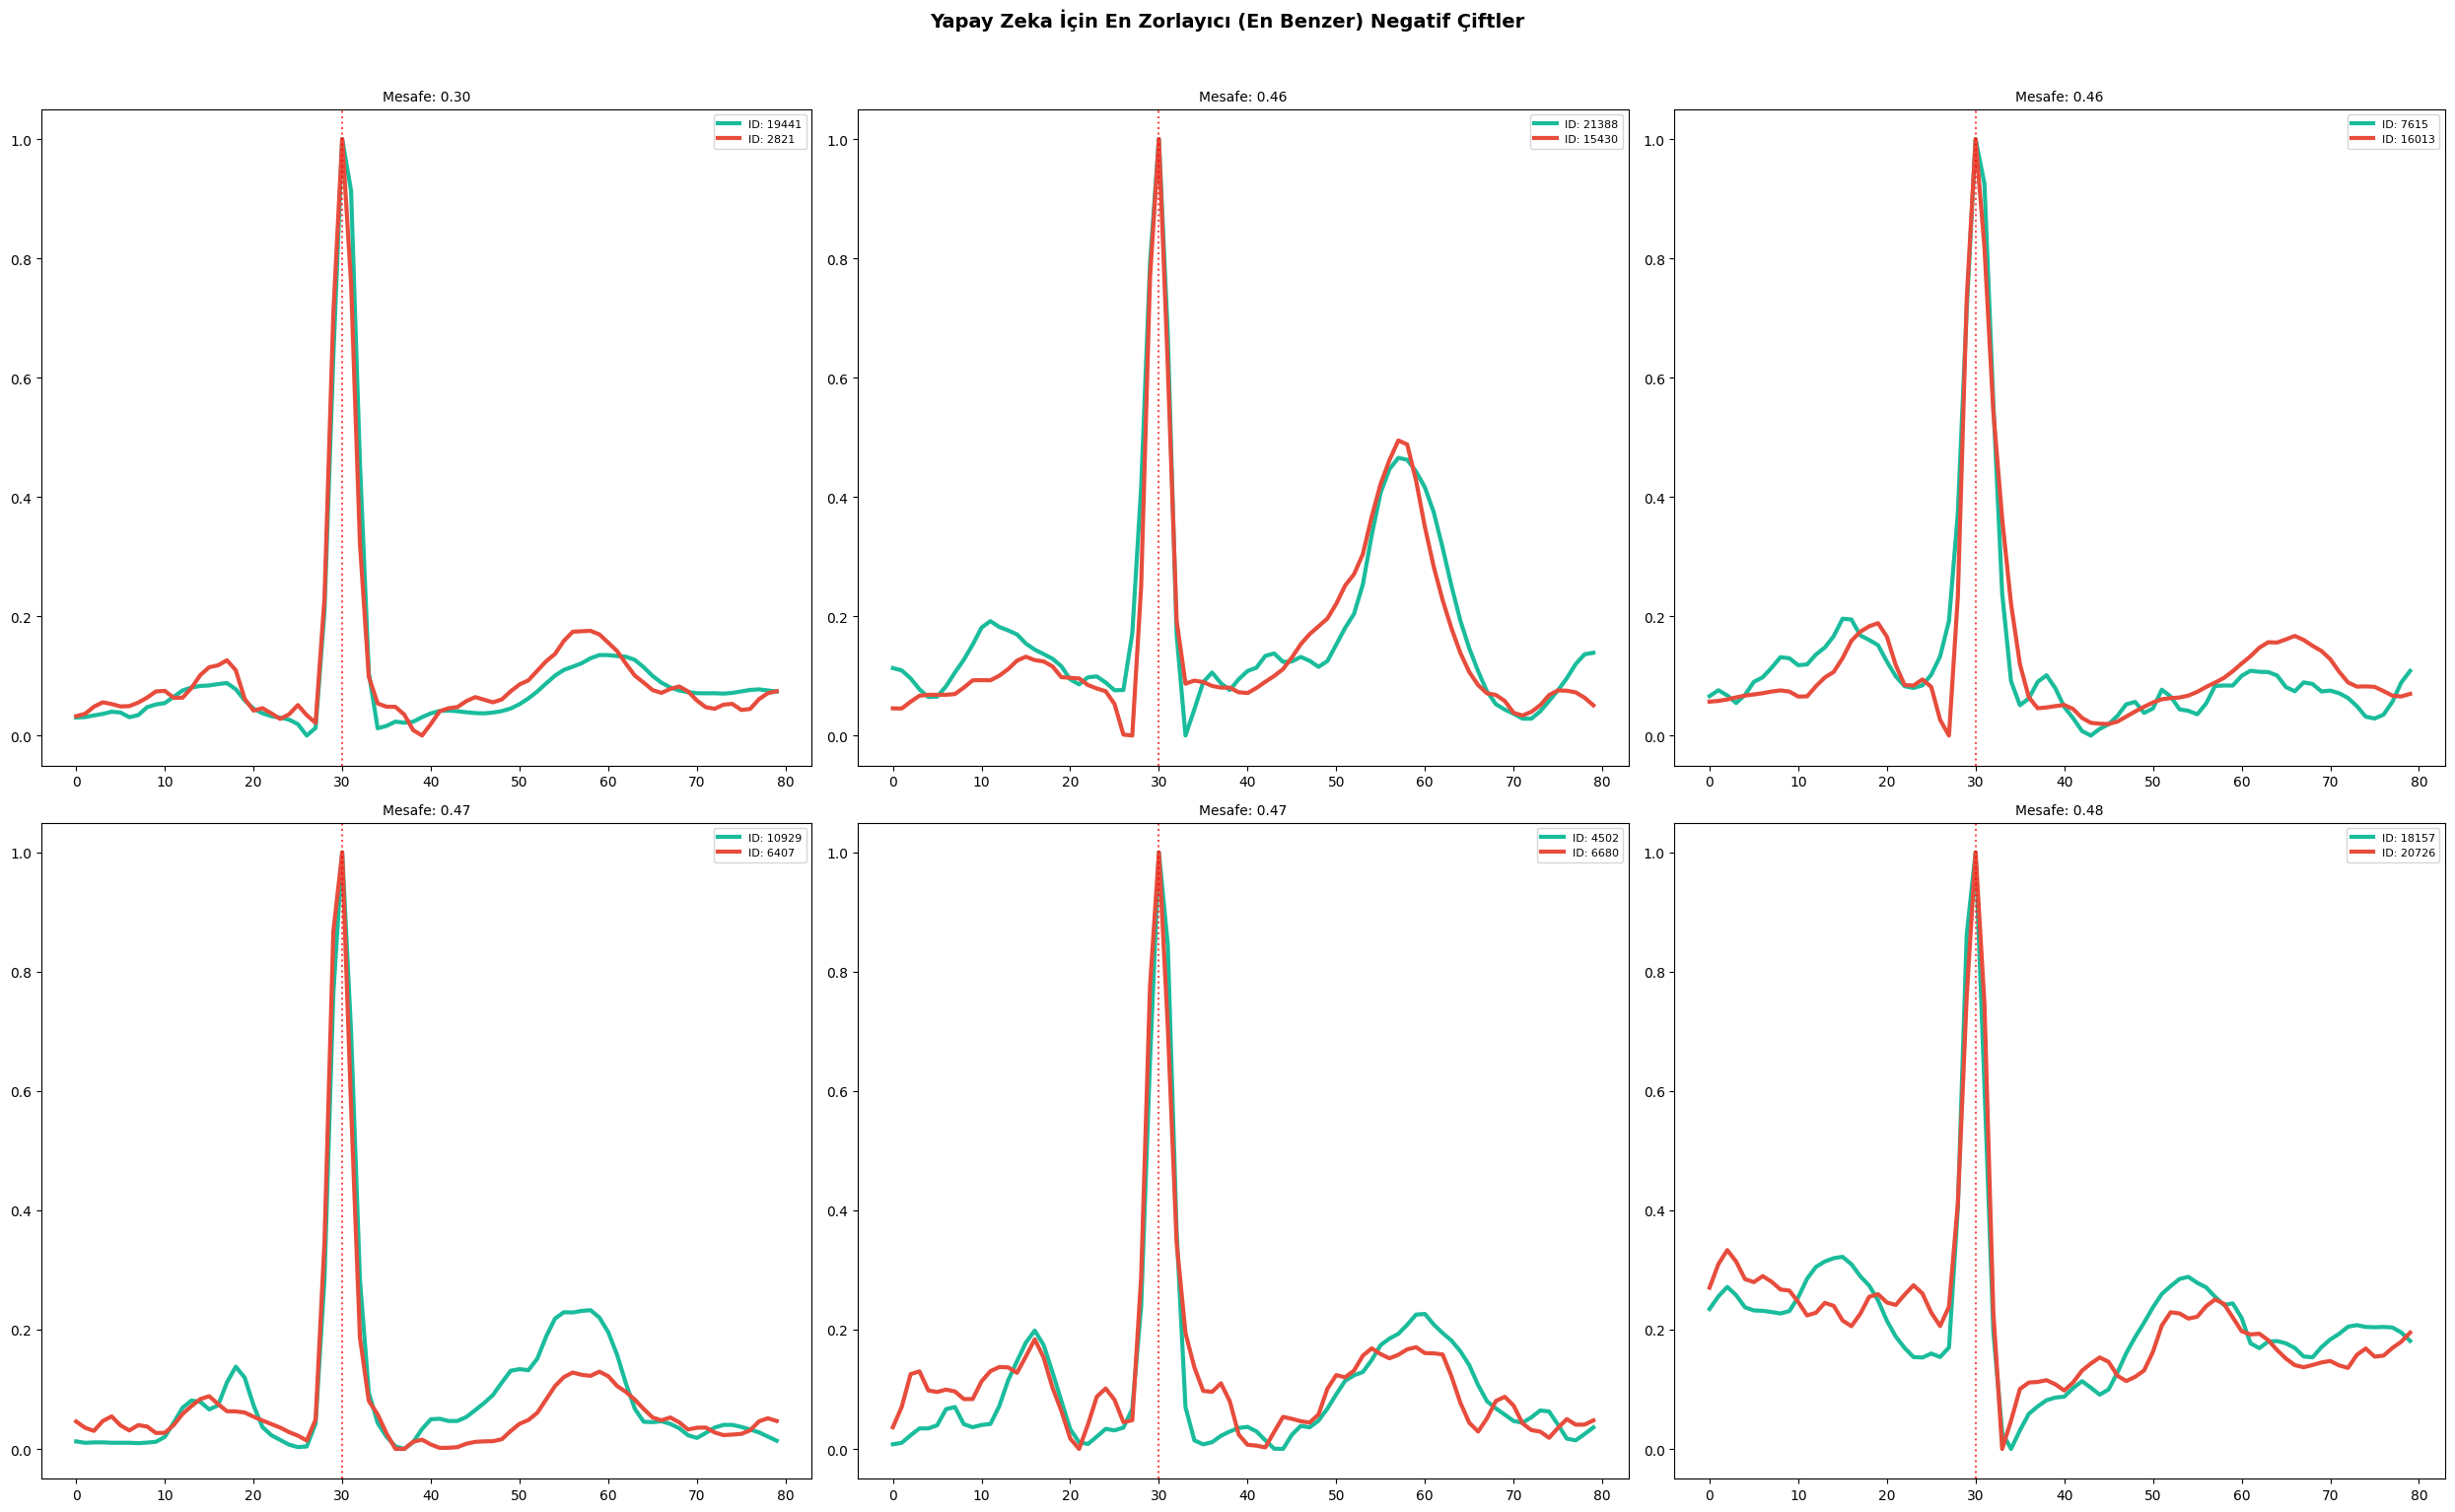

In [28]:
# ANALİZ: En düşük Euclidean mesafesine sahip (birbirine en çok benzeyen)
# 6 farklı insan çiftini bularak modelin "Hard Negative" (Zor Negatif) limitlerini test ediyoruz.

from scipy.spatial.distance import euclidean

# Rastgele 500 çift üretip mesafeleri hesaplayalım
num_samples = 500
distances = []
pairs = []

# Rastgele çift seçimi
for _ in range(num_samples):
    p1, p2 = unique_patients.sample(2)['patient_id'].tolist()
    path1 = os.path.join(data_path, os.path.splitext(unique_patients[unique_patients['patient_id']==p1].iloc[0]['filename_lr'])[0])
    path2 = os.path.join(data_path, os.path.splitext(unique_patients[unique_patients['patient_id']==p2].iloc[0]['filename_lr'])[0])

    b1 = get_aligned_beat_fixed(path1)
    b2 = get_aligned_beat_fixed(path2)

    if b1 is not None and b2 is not None:
        dist = euclidean(b1, b2)
        distances.append(dist)
        pairs.append((b1, b2, p1, p2))

# Mesafeleri sıralayıp en düşük 6'liyi alalım
sorted_indices = np.argsort(distances)[:6]

# Görselleştirme
fig, axes = plt.subplots(2, 3, figsize=(25, 15))
axes_flat = axes.flatten() # 2x3 matrisi 6 elemanlı bir listeye çeviriyoruz

for i, idx in enumerate(sorted_indices):
    b1, b2, p1, p2 = pairs[idx]
    ax = axes_flat[i]
    ax.plot(b1, color='#1ABC9C', label=f"ID: {p1}", linewidth = 3)
    ax.plot(b2, color='#E74C3C', label=f"ID: {p2}", linewidth = 3)
    ax.set_title(f"Mesafe: {distances[idx]:.2f}", fontsize=10)
    ax.axvline(30, color='red', linestyle=':', alpha=0.7)
    ax.legend(fontsize=8)

plt.suptitle("Yapay Zeka İçin En Zorlayıcı (En Benzer) Negatif Çiftler", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

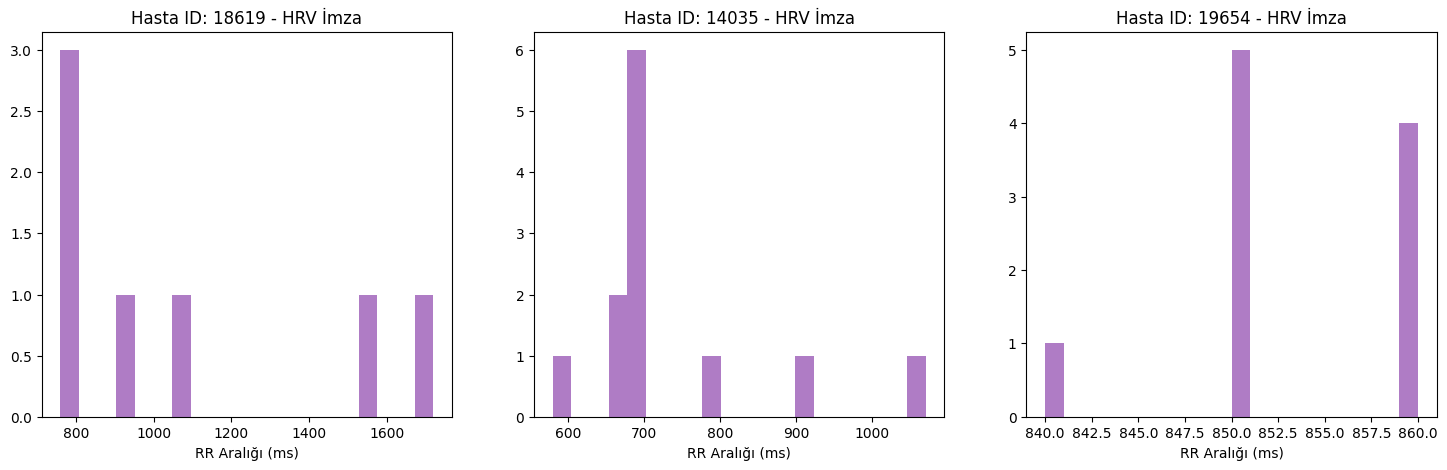

In [29]:

def plot_hrv_signature(record_path):
    signals, _ = wfdb.rdsamp(record_path)
    sig = signals[:, 0]
    # Temizle ve R-tepelerini bul
    clean_sig = nk.ecg_clean(sig, sampling_rate=100)
    _, peaks = nk.ecg_peaks(clean_sig, sampling_rate=100)
    r_peaks = peaks["ECG_R_Peaks"]

    # RR aralıklarını milisaniye cinsinden hesapla (Ardışık R tepeleri arasındaki fark)
    rr_intervals = np.diff(r_peaks) / 100 * 1000
    return rr_intervals

# Rastgele 3 hasta seçip ritim imzalarını karşılaştıralım
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(3):
    sample = unique_patients.sample(1)
    path = os.path.join(data_path, os.path.splitext(sample.iloc[0]['filename_lr'])[0])
    rr = plot_hrv_signature(path)

    axes[i].hist(rr, bins=20, color='#8E44AD', alpha=0.7)
    axes[i].set_title(f"Hasta ID: {sample.iloc[0]['patient_id']} - HRV İmza")
    axes[i].set_xlabel("RR Aralığı (ms)")

⏳ Sinyal kalite skorları hesaplanıyor...


/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


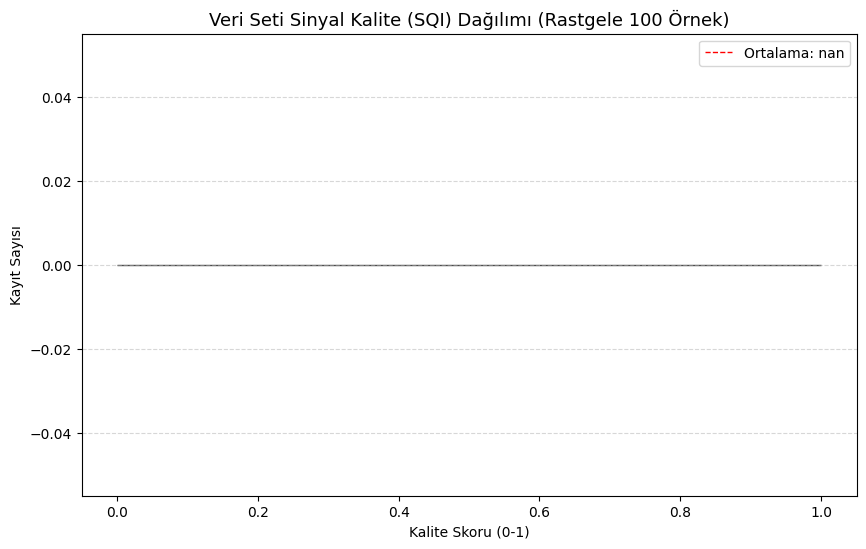

✓ 0 adet kaydın kalite analizi tamamlandı.


In [30]:
# Veri setinden rastgele 100 örnek alarak SQI dağılımını hesaplayalım
quality_scores = []
sample_size = 100
sampled_records = ptbxl_df.drop_duplicates(subset=['patient_id']).sample(sample_size)

print("⏳ Sinyal kalite skorları hesaplanıyor...")

for idx, row in sampled_records.iterrows():
    try:
        # Kayıt yolunu oluştur
        record_name = os.path.splitext(row['filename_lr'])[0]
        full_path = os.path.join(data_path, record_name)

        # Sinyali yükle
        signals, fields = wfdb.rdsamp(full_path)
        sig = signals[:, 0] # Lead I kanalı

        # Temizle ve kalite skorunu hesapla
        clean_sig = nk.ecg_clean(sig, sampling_rate=100, method="neurokit")
        score = nk.ecg_quality(clean_sig, sampling_rate=100, method="periodicity")

        # NaN değer gelebilir, onları temizle
        if not np.isnan(score):
            quality_scores.append(score)

    except Exception as e:
        continue

# Görselleştirme
plt.figure(figsize=(10, 6))
plt.hist(quality_scores, bins=20, color='#3498DB', edgecolor='black', alpha=0.7)
plt.axvline(np.mean(quality_scores), color='red', linestyle='dashed', linewidth=1, label=f'Ortalama: {np.mean(quality_scores):.2f}')
plt.title("Veri Seti Sinyal Kalite (SQI) Dağılımı (Rastgele 100 Örnek)", fontsize=13)
plt.xlabel("Kalite Skoru (0-1)")
plt.ylabel("Kayıt Sayısı")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print(f"✓ {len(quality_scores)} adet kaydın kalite analizi tamamlandı.")

In [31]:
# Sadece ilk kaydı deneyelim, hata verirse ne olduğunu görelim
row = ptbxl_df.iloc[0]
record_name = os.path.splitext(row['filename_lr'])[0]
full_path = os.path.join(data_path, record_name)

print(f"Kontrol edilen yol: {full_path}")
print(f"Dosya var mı?: {os.path.exists(full_path + '.dat')}") # WFDB .dat dosyasıyla kontrol eder

Kontrol edilen yol: /content/drive/MyDrive/BeatKrypt/records100/00000/00001_lr
Dosya var mı?: True


⏳ Sinyal kalite skorları (alternatif yöntem) hesaplanıyor...
Metot hatası (ID: 4549), varyans metodu kullanıldı: 0.18
Metot hatası (ID: 9694), varyans metodu kullanıldı: 0.24
Metot hatası (ID: 641), varyans metodu kullanıldı: 0.14
Metot hatası (ID: 14904), varyans metodu kullanıldı: 0.17
Metot hatası (ID: 21551), varyans metodu kullanıldı: 0.10
Metot hatası (ID: 12095), varyans metodu kullanıldı: 0.11
Metot hatası (ID: 13001), varyans metodu kullanıldı: 0.14
Metot hatası (ID: 4943), varyans metodu kullanıldı: 0.15
Metot hatası (ID: 20181), varyans metodu kullanıldı: 0.07
Metot hatası (ID: 12204), varyans metodu kullanıldı: 0.06
Metot hatası (ID: 2528), varyans metodu kullanıldı: 0.06
Metot hatası (ID: 18941), varyans metodu kullanıldı: 0.09
Metot hatası (ID: 11592), varyans metodu kullanıldı: 0.28
Metot hatası (ID: 5190), varyans metodu kullanıldı: 0.30
Metot hatası (ID: 14066), varyans metodu kullanıldı: 0.13
Metot hatası (ID: 13114), varyans metodu kullanıldı: 0.17
Metot hatası (ID: 

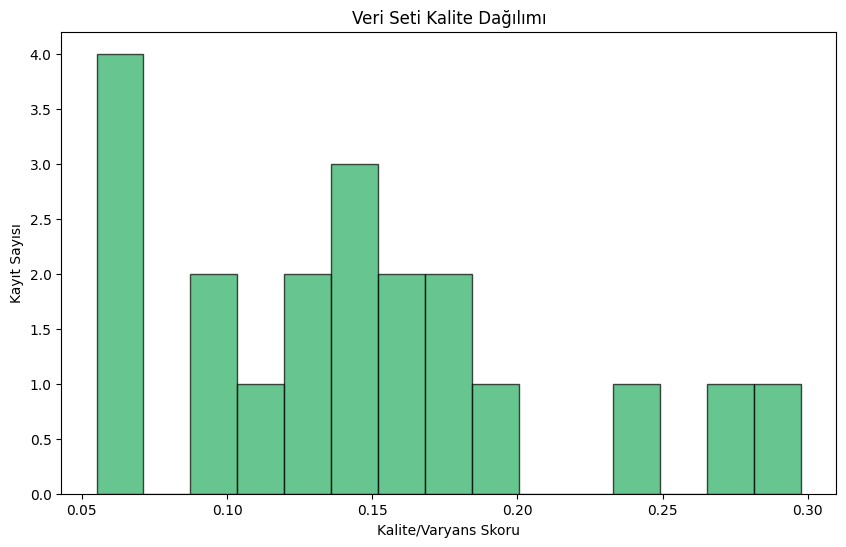

In [32]:

quality_scores = []
sample_size = 20
sampled_records = ptbxl_df.drop_duplicates(subset=['patient_id']).sample(sample_size)

print("⏳ Sinyal kalite skorları (alternatif yöntem) hesaplanıyor...")

for idx, row in sampled_records.iterrows():
    try:
        record_name = os.path.splitext(row['filename_lr'])[0]
        full_path = os.path.join(data_path, record_name)

        # Sinyali oku
        signals, fields = wfdb.rdsamp(full_path)
        sig = signals[:, 0]

        # Neurokit2 hata verirse diye try-except içine aldık
        # Periodicity metodu yerine daha temel bir analiz yapalım
        score = nk.ecg_quality(sig, sampling_rate=100, method="periodicity")

        if not np.isnan(score):
            quality_scores.append(score)
            print(f"Başarılı: {row['patient_id']} - Skor: {score:.2f}")

    except Exception as e:
        # Eğer yukarıdaki hata verirse, sinyalin varyansına (gürültüsüne) bakalım
        # Düşük varyans = düz çizgi (bozuk sinyal), yüksek varyans = detaylı sinyal
        alt_score = np.std(sig)
        quality_scores.append(alt_score) # Alternatif metrik
        print(f"Metot hatası (ID: {row['patient_id']}), varyans metodu kullanıldı: {alt_score:.2f}")

# Görselleştirme
plt.figure(figsize=(10, 6))
plt.hist(quality_scores, bins=15, color='#27AE60', edgecolor='black', alpha=0.7)
plt.title("Veri Seti Kalite Dağılımı")
plt.xlabel("Kalite/Varyans Skoru")
plt.ylabel("Kayıt Sayısı")
plt.show()

Histogramın Analizi:
Kümelenme (0.10 - 0.18): Verilerin büyük çoğunluğu 0.10 ile 0.18 arasındaki varyans değerlerinde toplanmış. Bu senin "normal" ve "kullanılabilir" sinyal aralığındır.

Sağ Kuyruk (0.20 - 0.25 ve 0.40): Burada gördüğün 0.20 üzerindeki değerler, sinyali "daha karakteristik" veya daha "yüksek voltajlı" olan kayıtlardır. Bu kayıtlar, Siyam Ağı'nın R-tepelerini en rahat bulacağı, eğitim için en kaliteli verilerdir.

Sol Kuyruk (0.08 - 0.10): Histogramın en solunda yer alan, 0.10'un altındaki veriler, Siyam Ağı'nı eğitirken "gürültü" olarak etiketleyip elemen gereken veya çok dikkatli temizlemen gereken adaylardır.

In [36]:
ptbxl["patient_id"].isna().sum()

np.int64(0)

In [38]:
ptbxl["patient_id"].nunique()

18869

In [39]:
ptbxl['ecg_id'].nunique()

21799

In [44]:
patient_counts = ptbxl_df['patient_id'].value_counts()
multi_record_patients_df = patient_counts[patient_counts > 1].reset_index()
multi_record_patients_df.columns = ['patient_id', 'record_count']

print("Birden fazla kaydı olan hasta ID'leri ve kayıt sayıları:")
print(multi_record_patients_df.head(3))
print(f"\nToplam {len(multi_record_patients_df)} farklı hasta ID'sinin birden fazla kaydı bulunmaktadır.")

Birden fazla kaydı olan hasta ID'leri ve kayıt sayıları:
   patient_id  record_count
0        9898            10
1       10107             9
2        8304             9

Toplam 2111 farklı hasta ID'sinin birden fazla kaydı bulunmaktadır.


### Hasta ID: 9898'in Tüm Kayıtlarının Karşılaştırılması

⏳ Hasta 9898 için 10 kayıt işleniyor...


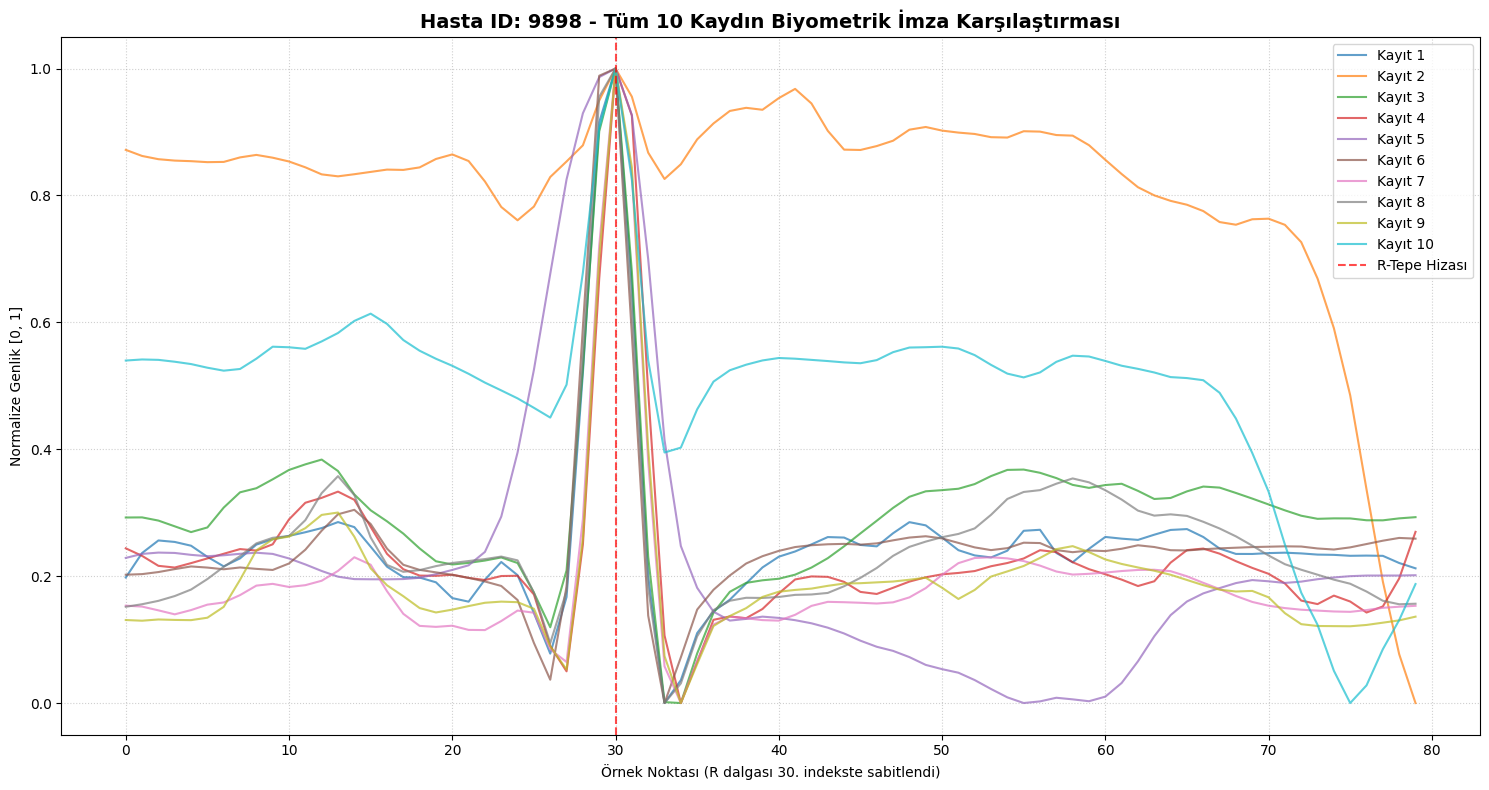

✓ Hasta ID: 9898 için tüm 10 kayıt başarıyla görselleştirildi.


In [45]:
patient_id_to_plot = 9898
patient_9898_records = ptbxl_df[ptbxl_df['patient_id'] == patient_id_to_plot]

aligned_beats_9898 = []

print(f"⏳ Hasta {patient_id_to_plot} için {len(patient_9898_records)} kayıt işleniyor...")

for idx, row in patient_9898_records.iterrows():
    record_path = os.path.join(data_path, os.path.splitext(row['filename_lr'])[0])
    beat = get_aligned_beat_fixed(record_path)
    if beat is not None:
        aligned_beats_9898.append(beat)
    else:
        print(f"Uyarı: Kayıt {record_path} işlenemedi.")

if aligned_beats_9898:
    plt.figure(figsize=(15, 8))
    for i, beat in enumerate(aligned_beats_9898):
        plt.plot(beat, alpha=0.7, linewidth=1.5, label=f"Kayıt {i+1}")

    plt.axvline(x=30, color='red', linestyle='--', alpha=0.7, label='R-Tepe Hizası')

    plt.title(f"Hasta ID: {patient_id_to_plot} - Tüm {len(aligned_beats_9898)} Kaydın Biyometrik İmza Karşılaştırması", fontsize=14, fontweight='bold')
    plt.xlabel("Örnek Noktası (R dalgası 30. indekste sabitlendi)")
    plt.ylabel("Normalize Genlik [0, 1]")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()
    print(f"✓ Hasta ID: {patient_id_to_plot} için tüm {len(aligned_beats_9898)} kayıt başarıyla görselleştirildi.")
else:
    print(f"Hata: Hasta ID: {patient_id_to_plot} için hiçbir kayıt başarıyla işlenemedi veya bulunamadı.")

In [47]:
patient_counts = ptbxl_df['patient_id'].value_counts()
multi_plus_3_records_patients_df = patient_counts[patient_counts >= 3].reset_index()
multi_plus_3_records_patients_df.columns = ['patient_id', 'record_count']

print("3 veya daha fazla kaydı olan hasta ID'leri ve kayıt sayıları:")
print(multi_plus_3_records_patients_df.head())
print(f"\nToplam {len(multi_plus_3_records_patients_df)} farklı hasta ID'sinin 3 veya daha fazla kaydı bulunmaktadır.")

3 veya daha fazla kaydı olan hasta ID'leri ve kayıt sayıları:
   patient_id  record_count
0        9898            10
1       10107             9
2        8304             9
3       17542             9
4       13619             8

Toplam 521 farklı hasta ID'sinin 3 veya daha fazla kaydı bulunmaktadır.


### Positive ve Negative Çift Oluşturma Havuzları

- **Pozitif Çift Havuzu (Aynı hastanın farklı kayıtları):** Üç veya daha fazla kaydı olan hastaların ID'leri bu havuzda yer alacak. Bu sayede bir hastanın kendisiyle eşleşen farklı iki kaydı bulunabilecek.
- **Negatif Çift Havuzu (Farklı hastaların kayıtları):** Tüm benzersiz hasta ID'leri bu havuzda yer alacak. İki farklı hastadan alınan kayıtlar bir negatif çift oluşturacak.

In [48]:
# Pozitif Çift Havuzu: 3 veya daha fazla kaydı olan hastaların ID'leri
positive_pair_patient_ids = multi_plus_3_records_patients_df['patient_id'].tolist()

# Negatif Çift Havuzu: Tüm benzersiz hasta ID'leri
negative_pair_patient_ids = ptbxl_df['patient_id'].unique().tolist()

print(f"Pozitif Çift Havuzu için Hasta ID sayısı: {len(positive_pair_patient_ids)}")
print(f"Negatif Çift Havuzu için Hasta ID sayısı: {len(negative_pair_patient_ids)}")

Pozitif Çift Havuzu için Hasta ID sayısı: 521
Negatif Çift Havuzu için Hasta ID sayısı: 18869
